# Análise exploratória
Análise sobre o dataset 911.csv

|**Nome:**|José Diniz Junior            |**RA:**|183134|
|-----|-----------------------------|---|------|
|**Nome:**|Roberto Leonardo Rodrigues   |**RA:**|060235|



In [2]:

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import matplotlib
%matplotlib inline

matplotlib.rcParams['font.size'] = 14
matplotlib.rcParams['figure.dpi'] = 150

import seaborn as sns

from IPython.core.pylabtools import figsize


In [3]:
df = pd.read_csv('911.csv', encoding='utf-8', quotechar='"')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99492 entries, 0 to 99491
Data columns (total 9 columns):
lat          99492 non-null float64
lng          99492 non-null float64
desc         99492 non-null object
zip          86637 non-null float64
title        99492 non-null object
timeStamp    99492 non-null object
twp          99449 non-null object
addr         98973 non-null object
e            99492 non-null int64
dtypes: float64(3), int64(1), object(5)
memory usage: 6.8+ MB


In [4]:
#EMS -> Emergency medical service
df['service'] = [words.split(sep=':')[0] for words in np.array(df.loc[:,'title'])]

In [5]:
df['subService'] = [words.split(sep=':')[1] for words in np.array(df.loc[:,'title'])]

In [6]:
df.service.value_counts()

EMS        48877
Traffic    35695
Fire       14920
Name: service, dtype: int64

In [7]:
df.groupby(by='service').subService.value_counts()

service  subService                   
EMS       RESPIRATORY EMERGENCY            5112
          CARDIAC EMERGENCY                5012
          FALL VICTIM                      4863
          VEHICLE ACCIDENT                 3935
          SUBJECT IN PAIN                  2687
          HEAD INJURY                      2631
          UNKNOWN MEDICAL EMERGENCY        1873
          SYNCOPAL EPISODE                 1717
          SEIZURES                         1630
          GENERAL WEAKNESS                 1464
          ABDOMINAL PAINS                  1436
          ALTERED MENTAL STATUS            1386
          MEDICAL ALERT ALARM              1342
          HEMORRHAGING                     1259
          CVA/STROKE                       1202
          OVERDOSE                         1191
          NAUSEA/VOMITING                  1131
          UNCONSCIOUS SUBJECT              1115
          DIABETIC EMERGENCY                836
          DIZZINESS                         799
 

In [8]:
df.timeStamp = pd.to_datetime(df.timeStamp)

In [9]:
df['hour'] = df.timeStamp.dt.hour
df['month'] = df.timeStamp.dt.month
df['dayOfWeek'] = df.timeStamp.dt.dayofweek

In [10]:
df[df['service']=='EMS'].groupby(['month','subService']).size()

month  subService                   
1       ABDOMINAL PAINS                 186
        ALLERGIC REACTION                45
        ALTERED MENTAL STATUS           160
        AMPUTATION                        4
        ANIMAL BITE                       8
        APPLIANCE FIRE                    1
        ASSAULT VICTIM                   60
        BACK PAINS/INJURY               108
        BUILDING FIRE                    23
        BURN VICTIM                       3
        CARBON MONOXIDE DETECTOR         14
        CARDIAC EMERGENCY               609
        CHOKING                          23
        CVA/STROKE                      177
        DEHYDRATION                      33
        DIABETIC EMERGENCY               93
        DIZZINESS                        91
        EMS SPECIAL SERVICE              14
        EYE INJURY                        7
        FALL VICTIM                     669
        FEVER                            70
        FIRE ALARM                     

In [11]:
df[df['service']=='EMS'].groupby(['month','subService']).size().reset_index(name='total')

,month,subService,total
0,1,ABDOMINAL PAINS,186
1,1,ALLERGIC REACTION,45
2,1,ALTERED MENTAL STATUS,160
3,1,AMPUTATION,4
4,1,ANIMAL BITE,8
5,1,APPLIANCE FIRE,1
6,1,ASSAULT VICTIM,60
7,1,BACK PAINS/INJURY,108
8,1,BUILDING FIRE,23
9,1,BURN VICTIM,3


In [12]:
ttt = df[df['service']=='EMS'].groupby(['month']).size()
ttt.sort_values()

month
12    3898
8     4508
2     5413
4     5680
6     5720
5     5734
3     5832
7     6029
1     6063
dtype: int64

In [14]:
df.groupby(['hour']).size().reset_index(name='total')

,hour,total
0,0,2112
1,1,1721
2,2,1549
3,3,1435
4,4,1418
5,5,1629
6,6,2513
7,7,3970
8,8,5044
9,9,5314


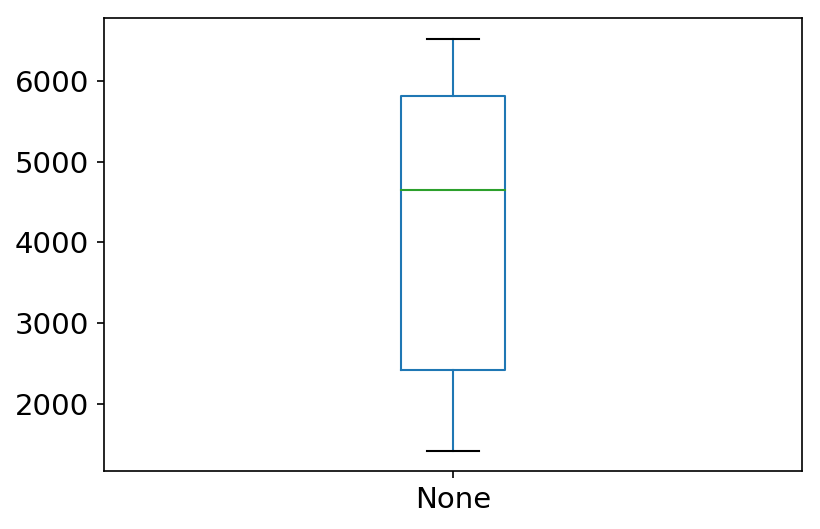

In [200]:
figsize(6, 4)
t = df.groupby(['hour']).size()
#dfa = pd.DataFrame(t)
#dfa.plot.box()
t.plot.box()
#fazer histograma por cidade

In [28]:
import seaborn as sns

In [35]:
t = df.groupby(['hour']).size().reset_index(name='total')
t

,hour,total
0,0,2112
1,1,1721
2,2,1549
3,3,1435
4,4,1418
5,5,1629
6,6,2513
7,7,3970
8,8,5044
9,9,5314


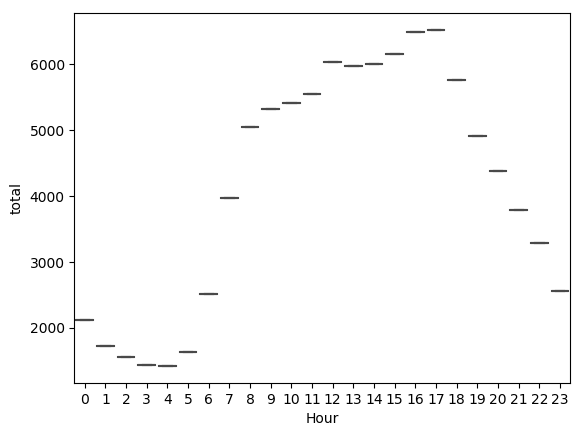

In [135]:
sns.boxplot(x="Hour", y="total",data=t,palette='rainbow')

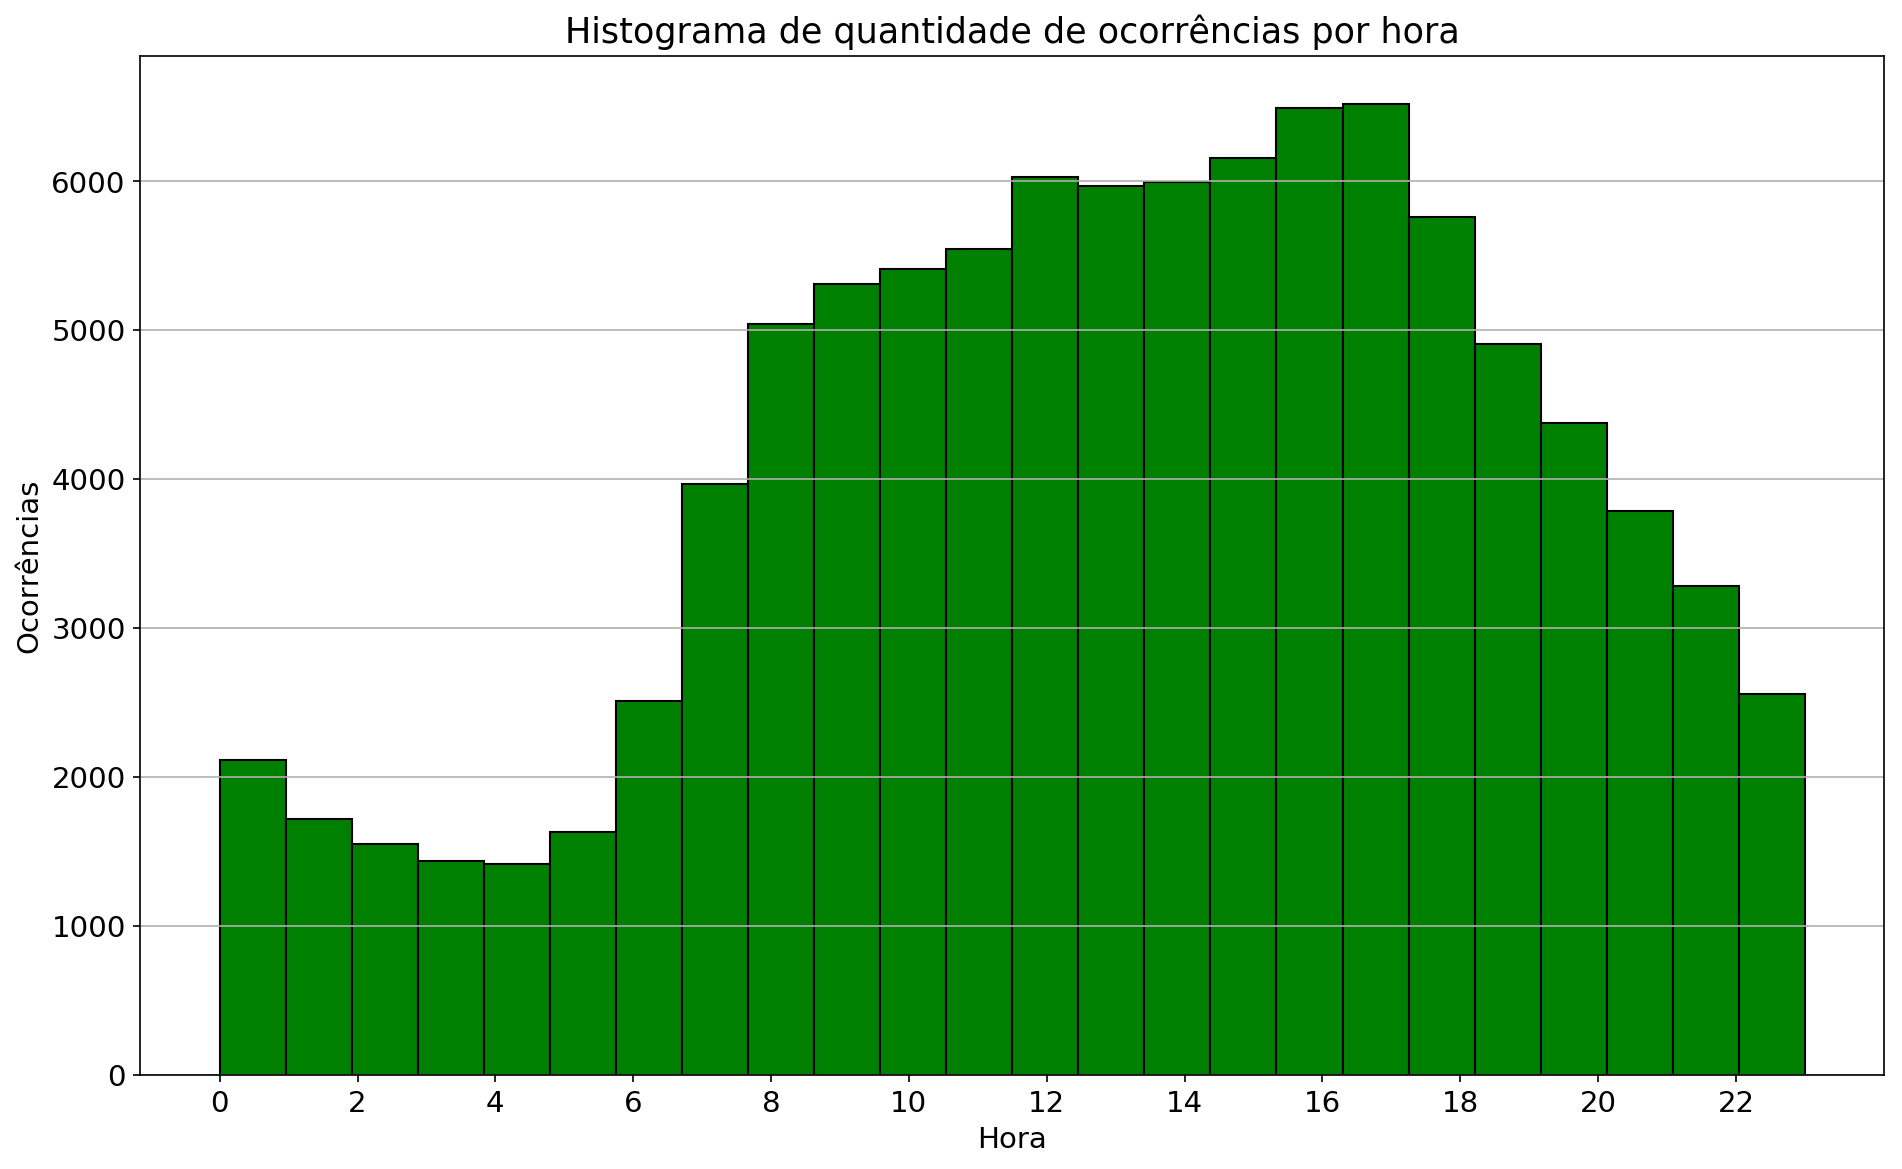

In [201]:
figsize(15,9)
# Make the histogram using matplotlib, bins must be integet
plt.hist(df.hour, color = 'green', edgecolor = 'black',
         bins = int(195/8))

plt.title('Histograma de quantidade de ocorrências por hora')
plt.xlabel('Hora'); 
plt.ylabel('Ocorrências');
plt.xticks(np.arange(0, 24, step=2))
plt.grid(axis='y')

In [183]:
services = df.groupby('service')['service'].count().index[:]
services

Index(['EMS', 'Fire', 'Traffic'], dtype='object', name='service')

In [ ]:
# Extract top five airlines with most flights
carrier_flights = pd.Series(flights.groupby('twp')['twp'].count())
carrier_flights = carrier_flights.sort_values(ascending=False)
top_five = carrier_flights.index[:5]

# Subset to the top 5 airlines
top_five_flights = flights[flights['name'].isin(top_five)]

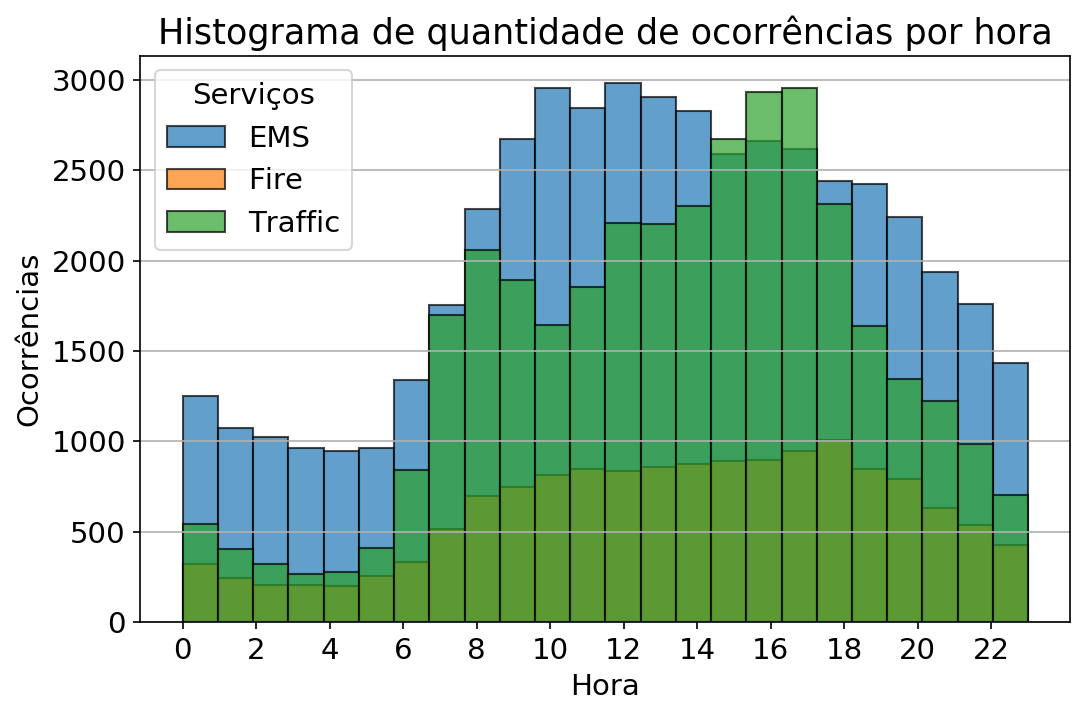

In [202]:
figsize(8, 5)
for srv in services:
    subset = df[df['service'] == srv]    
    plt.hist(subset['hour'], edgecolor = 'black',alpha=0.7,bins = int(195/8), label = srv)
    '''sns.distplot(subset['hour'], bins = int(195/8), 
                 label = srv, hist = False, kde = True,  
                 hist_kws = {'edgecolor': 'black'})'''
plt.legend(prop={'size': 14}, title = 'Serviços');plt.title('Histograma de quantidade de ocorrências por hora');
plt.xlabel('Hora'); plt.ylabel('Ocorrências');plt.xticks(np.arange(0, 24, step=2));plt.grid(axis='y')

In [233]:
totalService = df.groupby('hour')['service'].count().sort_index(ascending=False)
totalEMS = df[df['service']=='EMS'].groupby('hour')['service'].count().sort_index(ascending=False)
totalTrafic = df[df['service']=='Traffic'].groupby('hour')['service'].count().sort_index(ascending=False)
totalFire = df[df['service']=='Fire'].groupby('hour')['service'].count().sort_index(ascending=False)

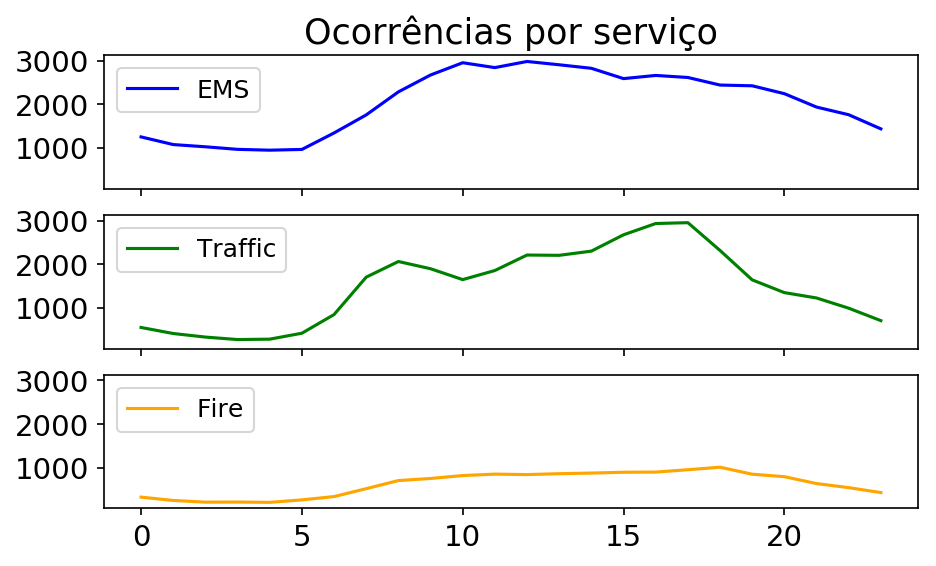

In [289]:
figsize(7,4)
f, (ax1, ax2, ax3) = plt.subplots(3, sharex=True, sharey=True)
ax1.set_title('Ocorrências por serviço')
ax1.plot(totalEMS , color='blue')
ax1.legend(('EMS',),loc='upper left', prop={'size': 12})
ax2.plot(totalTrafic, color='green', label='Traffic')
ax2.legend(('Traffic',), loc='upper left', prop={'size': 12})
ax3.plot(totalFire, color='orange')
ax3.legend(('Fire',), loc='upper left', prop={'size': 12})
#f.subplots_adjust(hspace=0)
plt.setp([a.get_xticklabels() for a in f.axes[:-1]], visible=False)


In [253]:
all = [totalService,totalEMS,totalTrafic,totalFire]

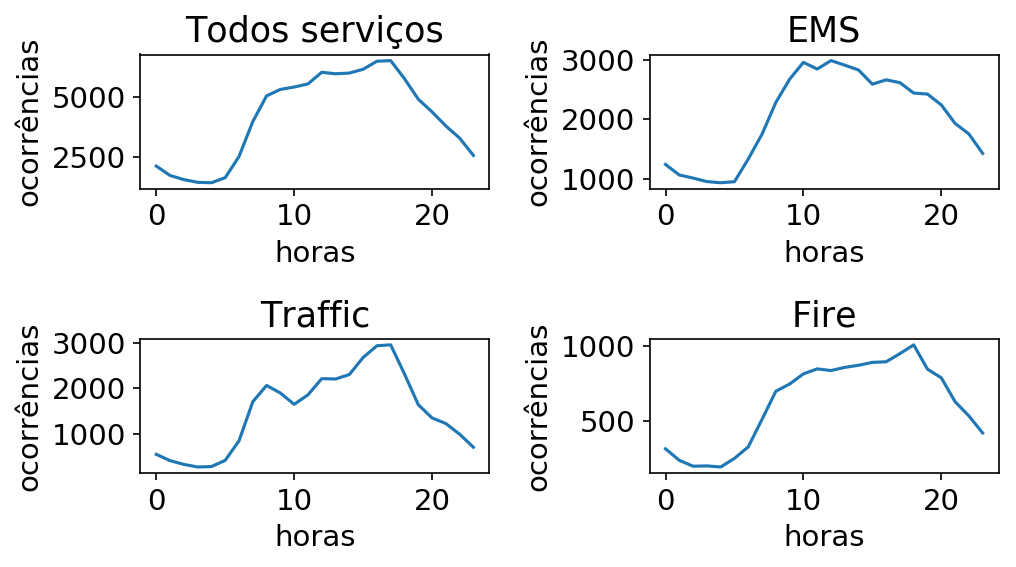

In [275]:
names = ['Todos serviços', 'EMS', 'Traffic', 'Fire']

figs, axes = plt.subplots(nrows=2,ncols=2)
idx = 0
for ir, row in enumerate(axes):
    for ic, col in enumerate(row):
        col.plot(all[idx])
        col.set_title(names[idx])  
        col.set_xlabel('horas')
        col.set_ylabel('ocorrências')
        idx+=1
                
figs.tight_layout()            
plt.show()

In [ ]:
# Extract top five airlines with most flights
carrier_flights = pd.Series(flights.groupby('twp')['twp'].count())
carrier_flights = carrier_flights.sort_values(ascending=False)
top_five = carrier_flights.index[:5]

# Subset to the top 5 airlines
top_five_flights = flights[flights['name'].isin(top_five)]

In [274]:
df.groupby(['twp','service','subService'])['subService'].count().reset_index(name='total').sort_values('total',ascending=False)

,twp,service,subService,total
1471,LOWER MERION,Traffic,VEHICLE ACCIDENT -,2324
3230,UPPER MERION,Traffic,VEHICLE ACCIDENT -,1712
73,ABINGTON,Traffic,VEHICLE ACCIDENT -,1338
382,CHELTENHAM,Traffic,VEHICLE ACCIDENT -,1210
2270,PLYMOUTH,Traffic,VEHICLE ACCIDENT -,951
2027,NORRISTOWN,Traffic,VEHICLE ACCIDENT -,939
1848,MONTGOMERY,Traffic,VEHICLE ACCIDENT -,914
3298,UPPER MORELAND,Traffic,VEHICLE ACCIDENT -,902
1081,HORSHAM,Traffic,VEHICLE ACCIDENT -,834
1468,LOWER MERION,Traffic,DISABLED VEHICLE -,787


In [ ]:
plt.plot(emergency.lat, emergency.lng, 'o', color='blue');
plt.title("Scatter Plot of Location of Calls")
plt.xlabel("Lattitude")
plt.ylabel("Longitutde")
plt.show()

In [22]:
df.head(10)

,lat,lng,desc,zip,title,timeStamp,twp,addr,e,Reason
0,40.297876,-75.581294,REINDEER CT & DEAD END; NEW HANOVER; Station ...,19525.0,EMS: BACK PAINS/INJURY,2015-12-10 17:40:00,NEW HANOVER,REINDEER CT & DEAD END,1,EMS
1,40.258061,-75.264680,BRIAR PATH & WHITEMARSH LN; HATFIELD TOWNSHIP...,19446.0,EMS: DIABETIC EMERGENCY,2015-12-10 17:40:00,HATFIELD TOWNSHIP,BRIAR PATH & WHITEMARSH LN,1,EMS
2,40.121182,-75.351975,HAWS AVE; NORRISTOWN; 2015-12-10 @ 14:39:21-St...,19401.0,Fire: GAS-ODOR/LEAK,2015-12-10 17:40:00,NORRISTOWN,HAWS AVE,1,Fire
3,40.116153,-75.343513,AIRY ST & SWEDE ST; NORRISTOWN; Station 308A;...,19401.0,EMS: CARDIAC EMERGENCY,2015-12-10 17:40:01,NORRISTOWN,AIRY ST & SWEDE ST,1,EMS
4,40.251492,-75.603350,CHERRYWOOD CT & DEAD END; LOWER POTTSGROVE; S...,NaN,EMS: DIZZINESS,2015-12-10 17:40:01,LOWER POTTSGROVE,CHERRYWOOD CT & DEAD END,1,EMS
5,40.253473,-75.283245,CANNON AVE & W 9TH ST; LANSDALE; Station 345;...,19446.0,EMS: HEAD INJURY,2015-12-10 17:40:01,LANSDALE,CANNON AVE & W 9TH ST,1,EMS
6,40.182111,-75.127795,LAUREL AVE & OAKDALE AVE; HORSHAM; Station 35...,19044.0,EMS: NAUSEA/VOMITING,2015-12-10 17:40:01,HORSHAM,LAUREL AVE & OAKDALE AVE,1,EMS
7,40.217286,-75.405182,COLLEGEVILLE RD & LYWISKI RD; SKIPPACK; Stati...,19426.0,EMS: RESPIRATORY EMERGENCY,2015-12-10 17:40:01,SKIPPACK,COLLEGEVILLE RD & LYWISKI RD,1,EMS
8,40.289027,-75.399590,MAIN ST & OLD SUMNEYTOWN PIKE; LOWER SALFORD;...,19438.0,EMS: SYNCOPAL EPISODE,2015-12-10 17:40:01,LOWER SALFORD,MAIN ST & OLD SUMNEYTOWN PIKE,1,EMS
9,40.102398,-75.291458,BLUEROUTE & RAMP I476 NB TO CHEMICAL RD; PLYM...,19462.0,Traffic: VEHICLE ACCIDENT -,2015-12-10 17:40:01,PLYMOUTH,BLUEROUTE & RAMP I476 NB TO CHEMICAL RD,1,Traffic


In [4]:
df.describe()

,lat,lng,zip,e
count,99492.000000,99492.000000,86637.000000,99492.0
mean,40.159526,-75.317464,19237.658298,1.0
std,0.094446,0.174826,345.344914,0.0
min,30.333596,-95.595595,17752.000000,1.0
25%,40.100423,-75.392104,19038.000000,1.0
50%,40.145223,-75.304667,19401.000000,1.0
75%,40.229008,-75.212513,19446.000000,1.0
max,41.167156,-74.995041,77316.000000,1.0


In [5]:
df.isna().sum()

lat              0
lng              0
desc             0
zip          12855
title            0
timeStamp        0
twp             43
addr           519
e                0
dtype: int64

In [52]:
teste = df.groupby(by='title').twp.value_counts()
a = pd.DataFrame(teste)
a

twp
title                           twp                   
EMS: ABDOMINAL PAINS            NORRISTOWN         177
                                POTTSTOWN          114
                                ABINGTON            85
                                LOWER MERION        83
                                UPPER MORELAND      52
                                UPPER MERION        48
                                SPRINGFIELD         46
                                HORSHAM             42
                                LOWER PROVIDENCE    41
                                CHELTENHAM          40
                                LOWER SALFORD       39
                                LOWER POTTSGROVE    34
                                MONTGOMERY          31
                                EAST NORRITON       29
                                LANSDALE            29
                                LIMERICK            29
                                UPPER PROVIDENCE    29
                                UPPER GWYNEDD       24
                                WHITEMARSH          23
                                HATFIELD TOWNSHIP   22
                                PLYMOUTH            22
                                LOWER GWYNEDD       21
                                TOWAMENCIN          21
                                UPPER DUBLIN        20
                                WEST NORRITON       20
                                CHESTER COUNTY      18
                                DOUGLASS            18
                                SKIPPACK            18
                                FRANCONIA           15
                                LOWER MORELAND      15
...                                                ...
Traffic: VEHICLE LEAKING FUEL - PLYMOUTH             5
                                ABINGTON             4
                                CHESTER COUNTY       4
                                MONTGOMERY           4
                                TOWAMENCIN           4
                                LOWER MERION         3
                                UPPER PROVIDENCE     3
                                WHITPAIN             3
                                BRIDGEPORT           2
                                HATFIELD TOWNSHIP    2
                                LIMERICK             2
                                LOWER MORELAND       2
                                WEST NORRITON        2
                                WHITEMARSH           2
                                AMBLER               1
                                CHELTENHAM           1
                                CONSHOHOCKEN         1
                                JENKINTOWN           1
                                LANSDALE             1
                                LOWER POTTSGROVE     1
                                LOWER PROVIDENCE     1
                                NEW HANOVER          1
                                ROYERSFORD           1
                                UPPER DUBLIN         1
                                UPPER GWYNEDD        1
                                UPPER MORELAND       1
                                UPPER POTTSGROVE     1
                                UPPER SALFORD        1
                                WEST CONSHOHOCKEN    1
                                WEST POTTSGROVE      1

[3831 rows x 1 columns]

In [137]:
from pandas.plotting import scatter_matrix

array([[<matplotlib.axes._subplots.AxesSubplot object at 0x0000021C02E405C0>,
      dtype=object)

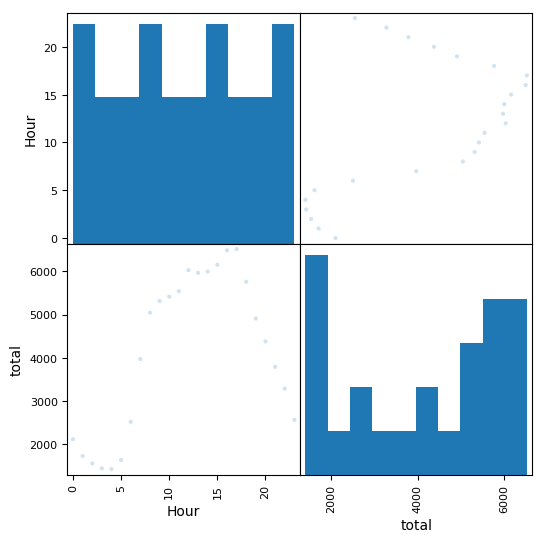

In [138]:
dfa = pd.DataFrame(t)
scatter_matrix(dfa, alpha=0.2, figsize=(6, 6), diagonal='hist')

In [ ]:
teste.plot.bar()

In [ ]:
1-box plot
2-regiao sem outliers
3-grafico/barra
4-dispersão

In [59]:
import matplotlib as mpl

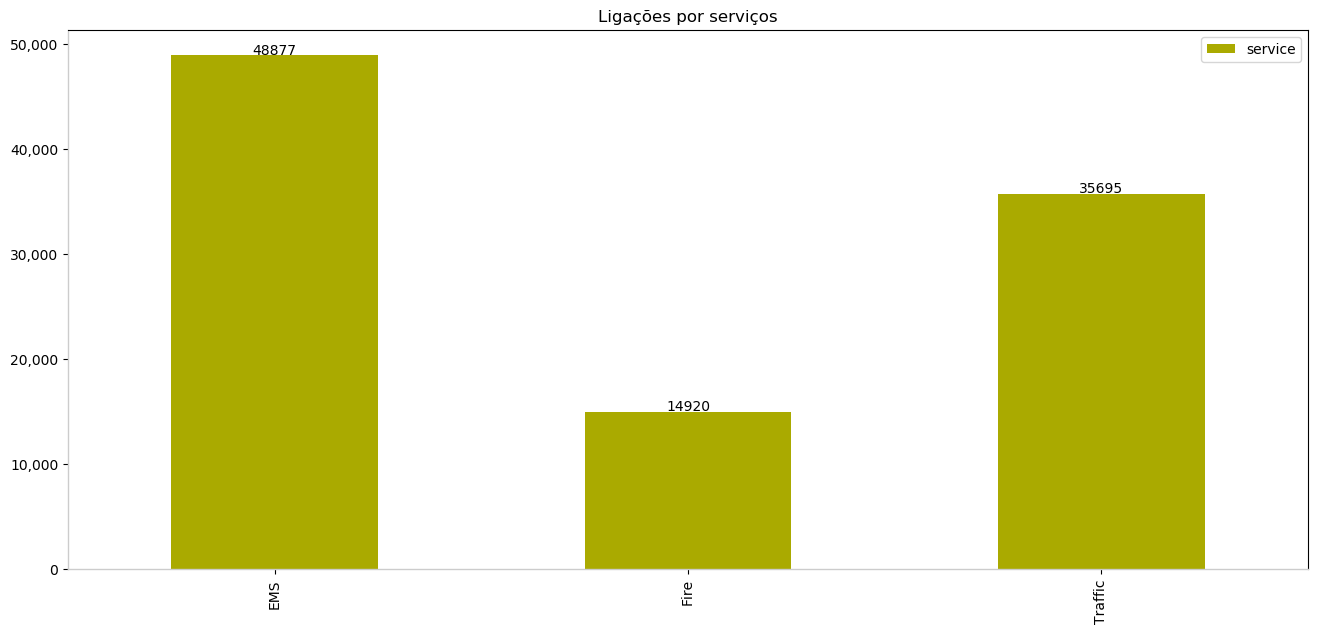

In [66]:
mpl.rcParams.update(mpl.rcParamsDefault)
data = pd.DataFrame(df.service.value_counts().sort_index())

ax = data.plot(kind='bar', color='#AAAA00',figsize=(16,7))
total = ["{}".format(int(row.service)) for name,row in data.iterrows()]
for i,child in enumerate(ax.get_children()[:data.index.size]):
    ax.text(i,child.get_bbox().y1+110,total[i], horizontalalignment ='center')

ax.get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: "{:,}".format(int(x))))
ax.patch.set_facecolor('#FFFFFF')
ax.spines['bottom'].set_color('#CCCCCC')
ax.spines['bottom'].set_linewidth(1)
ax.spines['left'].set_color('#CCCCCC')
ax.spines['left'].set_linewidth(1)
plt.title("Ligações por serviços")
plt.xticks(rotation=90)
plt.show()